In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

ames_data = pd.read_csv("../datasets/fe-course-data/ames.csv")
ames_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YearSold,SaleType,SaleCondition,SalePrice
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141.0,31770.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,5,2010,WD,Normal,215000
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80.0,11622.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,6,2010,WD,Normal,105000
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81.0,14267.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,Gar2,12500.0,6,2010,WD,Normal,172000
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93.0,11160.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,4,2010,WD,Normal,244000
4,Two_Story_1946_and_Newer,Residential_Low_Density,74.0,13830.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,Split_or_Multilevel,Residential_Low_Density,37.0,7937.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,CulDSac,...,0.0,No_Pool,Good_Privacy,NaN,0.0,3,2006,WD,Normal,142500
2926,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,0.0,8885.0,Pave,No_Alley_Access,Slightly_Irregular,Low,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,6,2006,WD,Normal,131000
2927,Split_Foyer,Residential_Low_Density,62.0,10441.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,Shed,700.0,7,2006,WD,Normal,132000
2928,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,77.0,10010.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,0.0,No_Pool,No_Fence,NaN,0.0,4,2006,WD,Normal,170000


In [2]:
from sklearn.decomposition import PCA

def apply_pca(X, standardize=True):
    if standardize:
        X = (X - X.mean(axis=0)) / X.std(axis=0)

    pca = PCA()
    X_pca = pca.fit_transform(X)
    component_names = [f"PC{i+1}" for i in range(X_pca.shape[1])]

    # Convert to dataframe
    X_pca = pd.DataFrame(X_pca, columns=component_names)
    
    # Create loadings
    loadings = pd.DataFrame(
        pca.components_.T,  # transpose the matrix of loadings
        columns=component_names,  # so the columns are the principal components
        index=X.columns,  # and the rows are the original features
    )
    return pca, X_pca, loadings


def plot_variance(pca, width=8, dpi=100):
    fig, axs = plt.subplots(1, 2)
    fig.set(figwidth=8, dpi=100)
    
    n = pca.n_components_
    grid = np.arange(1, n + 1)
    
    # Explained variance
    evr = pca.explained_variance_ratio_
    axs[0].bar(grid, evr)
    axs[0].set(
        xlabel="Component", title="% Explained Variance", ylim=(0.0, 1.0)
    )
    # Cumulative Variance
    cv = np.cumsum(evr)
    axs[1].plot(np.r_[0, grid], np.r_[0, cv], "o-")
    axs[1].set(
        xlabel="Component", title="% Cumulative Variance", ylim=(0.0, 1.0)
    )

    return axs

In [3]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor

def make_mi_scores(X, y):
    X = X.copy()
    for colname in X.select_dtypes(["object", "category"]):
        X[colname], _ = X[colname].factorize()
    # All discrete features should now have integer dtypes
    discrete_features = [pd.api.types.is_integer_dtype(t) for t in X.dtypes]
    mi_scores = mutual_info_regression(X, y, discrete_features=discrete_features, random_state=0)
    mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
    mi_scores = mi_scores.sort_values(ascending=False)
    return mi_scores


def score_dataset(X, y, model=None):
    if model is None:
        model = XGBRegressor(random_state=0)
    
    # Label encoding for categoricals
    for colname in X.select_dtypes(["category", "object"]):
        X[colname] =  X[colname].astype(str).fillna("missing")
        X[colname], _ = X[colname].factorize()
    
    # Metric for Housing competition is RMSLE (Root Mean Squared Log Error)
    score = cross_val_score(
        model, X, y, cv=5, scoring="neg_mean_squared_log_error",
    )
    score = -1 * score.mean()
    score = np.sqrt(score)
    return score

In [9]:
### Interpret Component Loadings
features = [
    "GarageArea",
    "YearRemodAdd",
    "TotalBsmtSF",
    "GrLivArea",
]

corr_with_price = ames_data[features].corrwith(ames_data.SalePrice)
corr_with_price

GarageArea      0.640138
YearRemodAdd    0.532974
TotalBsmtSF     0.632529
GrLivArea       0.706780
dtype: float64

In [5]:
X = ames_data.copy()
y = X.pop("SalePrice")
X = X.loc[:, features]

# `apply_pca`, defined above, reproduces the code from the tutorial
pca, X_pca, loadings = apply_pca(X)

In [6]:
from IPython.display import display, Markdown

content = f"""
### Loadings:
{loadings.to_markdown(index=True)}

**Q**: **Look at the loadings for components PC1 and PC3 (higher correlations to SalePrice).
Can you think of a description of what kind of contrast each component has captured?**<br>
**A**: The first component, PC1, seems to be a kind of "size" component: all of the features have the 
same sign (positive), indicating that this component is describing a contrast between houses having 
large values and houses having small values for these features.

The interpretation of the third component PC3 is a little trickier. The features `GarageArea` and 
`YearRemodAdd` both have near-zero loadings, so they should be ignored. This component is mostly
about `TotalBsmtSF` and `GrLivArea`. It describes a contrast between houses with a lot of living area
but small (or non-existant) basements, and the opposite: small houses with large basements.
"""

display(Markdown(content))


### Loadings:
|              |      PC1 |       PC2 |        PC3 |       PC4 |
|:-------------|---------:|----------:|-----------:|----------:|
| GarageArea   | 0.541229 | -0.102375 | -0.0384696 |  0.833733 |
| YearRemodAdd | 0.427077 |  0.886612 | -0.0490615 | -0.170639 |
| TotalBsmtSF  | 0.510076 | -0.360778 | -0.666836  | -0.406192 |
| GrLivArea    | 0.514294 | -0.2707   |  0.742592  | -0.332837 |

**Q**: **Look at the loadings for components PC1 and PC3 (higher correlations to SalePrice).
Can you think of a description of what kind of contrast each component has captured?**<br>
**A**: The first component, PC1, seems to be a kind of "size" component: all of the features have the 
same sign (positive), indicating that this component is describing a contrast between houses having 
large values and houses having small values for these features.

The interpretation of the third component PC3 is a little trickier. The features `GarageArea` and 
`YearRemodAdd` both have near-zero loadings, so they should be ignored. This component is mostly
about `TotalBsmtSF` and `GrLivArea`. It describes a contrast between houses with a lot of living area
but small (or non-existant) basements, and the opposite: small houses with large basements.


In [7]:
### Create new features
X = ames_data.copy()
y = X.pop("SalePrice")

# YOUR CODE HERE: Add new features to X.
X["Feature1"] = X.GrLivArea + X.TotalBsmtSF

score = score_dataset(X, y)
print(f"Your score: {score:.5f} RMSLE")

/opt/conda/lib/python3.11/site-packages/sklearn/utils/_tags.py:354: FutureWarning: The XGBRegressor or classes from which it inherits use `_get_tags` and `_more_tags`. Please define the `__sklearn_tags__` method, or inherit from `sklearn.base.BaseEstimator` and/or other appropriate mixins such as `sklearn.base.TransformerMixin`, `sklearn.base.ClassifierMixin`, `sklearn.base.RegressorMixin`, and `sklearn.base.OutlierMixin`. From scikit-learn 1.7, not defining `__sklearn_tags__` will raise an error.
  warnings.warn(


AttributeError: 'super' object has no attribute '__sklearn_tags__'

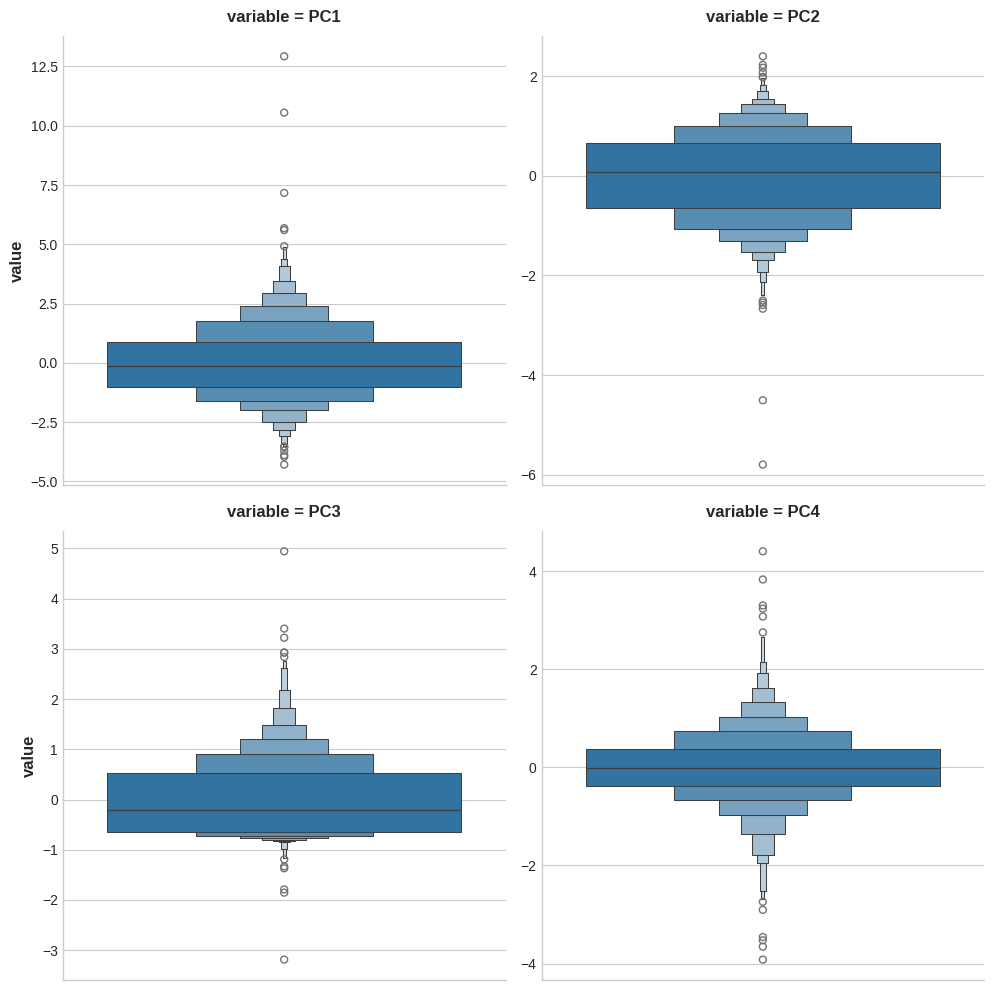

In [10]:
sns.catplot(
    y="value",
    col="variable",
    data=X_pca.melt(),
    kind='boxen',
    sharey=False,
    col_wrap=2,
);

In [17]:
component = "PC1"
idx = X_pca[component].sort_values(ascending=False).index
ames_data.loc[idx, ["SalePrice", "Neighborhood", "SaleCondition"] + features]

,SalePrice,Neighborhood,SaleCondition,GarageArea,YearRemodAdd,TotalBsmtSF,GrLivArea
1498,160000,Edwards,Partial,1418.0,2008,6110.0,5642.0
2180,183850,Edwards,Partial,1154.0,2009,5095.0,5095.0
2181,184750,Edwards,Partial,884.0,2008,3138.0,4676.0
1760,745000,Northridge,Abnorml,813.0,1996,2396.0,4476.0
1767,755000,Northridge,Normal,832.0,1995,2444.0,4316.0
...,...,...,...,...,...,...,...
662,59000,Old_Town,Normal,0.0,1950,416.0,599.0
2679,80500,Brookside,Normal,0.0,1950,0.0,912.0
2879,51689,Iowa_DOT_and_Rail_Road,Abnorml,0.0,1950,0.0,729.0
780,63900,Sawyer,Normal,0.0,1950,0.0,660.0


In [18]:
component = "PC2"
idx = X_pca[component].sort_values(ascending=False).index
ames_data.loc[idx, ["SalePrice", "Neighborhood", "SaleCondition"] + features]

,SalePrice,Neighborhood,SaleCondition,GarageArea,YearRemodAdd,TotalBsmtSF,GrLivArea
273,84900,Edwards,Normal,240.0,2007,0.0,640.0
154,107500,North_Ames,Normal,392.0,2007,0.0,827.0
243,84900,Edwards,Abnorml,308.0,2006,0.0,930.0
1220,52000,Brookside,Normal,0.0,2003,270.0,729.0
1283,143000,Old_Town,Abnorml,308.0,2008,192.0,1133.0
...,...,...,...,...,...,...,...
1288,256000,Old_Town,Normal,520.0,1950,1510.0,2792.0
2181,184750,Edwards,Partial,884.0,2008,3138.0,4676.0
2561,137900,North_Ames,Normal,528.0,1951,2136.0,2136.0
2180,183850,Edwards,Partial,1154.0,2009,5095.0,5095.0


In [19]:
component = "PC3"
idx = X_pca[component].sort_values(ascending=False).index
ames_data.loc[idx, ["SalePrice", "Neighborhood", "SaleCondition"] + features]

,SalePrice,Neighborhood,SaleCondition,GarageArea,YearRemodAdd,TotalBsmtSF,GrLivArea
1497,284700,Edwards,Normal,624.0,1996,0.0,3820.0
290,160000,South_and_West_of_Iowa_State_University,Normal,0.0,1967,0.0,2650.0
1537,381000,Crawford,Normal,1014.0,1997,728.0,3447.0
2666,475000,Old_Town,Normal,840.0,1993,1107.0,3608.0
2230,315000,Crawford,Normal,691.0,1986,279.0,2726.0
...,...,...,...,...,...,...,...
1656,170000,Northwest_Ames,Normal,944.0,1971,1625.0,1220.0
1637,591587,Stone_Brook,Partial,1110.0,2007,2660.0,2338.0
1498,160000,Edwards,Partial,1418.0,2008,6110.0,5642.0
423,555000,Northridge_Heights,Normal,672.0,2008,3094.0,2402.0


In [20]:
component = "PC4"
idx = X_pca[component].sort_values(ascending=False).index
ames_data.loc[idx, ["SalePrice", "Neighborhood", "SaleCondition"] + features]

,SalePrice,Neighborhood,SaleCondition,GarageArea,YearRemodAdd,TotalBsmtSF,GrLivArea
1258,139000,Old_Town,Normal,1488.0,1950,892.0,1436.0
1557,81000,Iowa_DOT_and_Rail_Road,Normal,1248.0,1950,894.0,894.0
746,126500,Brookside,Normal,1184.0,1950,1072.0,1072.0
2282,168000,Mitchell,Normal,1356.0,1975,1249.0,1622.0
2278,130000,Mitchell,Normal,1041.0,1953,0.0,2034.0
...,...,...,...,...,...,...,...
1772,430000,Northridge,Normal,546.0,1993,3200.0,3228.0
2045,200500,Clear_Creek,Normal,0.0,1994,1598.0,3086.0
2194,200000,South_and_West_of_Iowa_State_University,Abnorml,0.0,1995,1440.0,3395.0
2180,183850,Edwards,Partial,1154.0,2009,5095.0,5095.0


In [15]:
content = f"""
**Q**: **Do you notice any patterns in the extreme values? Does it seem like the outliers 
are coming from some special subset of the data?**<br>
**A**: several dwellings listed as Partial sales in the Edwards neighborhood that stand out. 
A partial sale is what occurs when there are multiple owners of a property and one or more of them sell 
their "partial" ownership of the property.

These kinds of sales are often happen during the settlement of a family estate or the dissolution 
of a business and aren't advertised publicly. If you were trying to predict the value of a house on 
the open market, you would probably be justified in removing sales like these from your dataset -- 
they are truly outliers.
"""

display(Markdown(content))


**Q**: **Do you notice any patterns in the extreme values? Does it seem like the outliers 
are coming from some special subset of the data?**<br>
**A**: several dwellings listed as Partial sales in the Edwards neighborhood that stand out. 
A partial sale is what occurs when there are multiple owners of a property and one or more of them sell 
their "partial" ownership of the property.

These kinds of sales are often happen during the settlement of a family estate or the dissolution 
of a business and aren't advertised publicly. If you were trying to predict the value of a house on 
the open market, you would probably be justified in removing sales like these from your dataset -- 
they are truly outliers.
